# 03 — Error analysis of the final classifier (B7 / B9)

Owner: Robin. Which clause types does fine-tuned Legal-BERT (`legal-bert_final_20261019-1523`) fix compared with the
TF-IDF + LogReg baseline (`tfidf-logreg_baseline_20261023`), where does it still fail, and why?

**Protocol.** Both models were evaluated **once** on the 2019 test set; this notebook only *reads* their saved test
predictions. Nothing here is tuned or selected: it is a descriptive view, so the numbers can be reported but must not
feed back into model choices. The confidence threshold 0.892 was chosen on **validation** (A9,
`results/calibration_legal-bert_final_20261019-1523.json`).

**Inputs** (gitignored, `results/predictions/`):
- `legal-bert_final_20261019-1523_test.parquet` — from `scripts/evaluate_checkpoint.py` (notebook 04);
- `tfidf-logreg_baseline_20261023_test.parquet` — from notebook 01, or `python scripts/regenerate_tfidf_predictions.py`
  (refits the same configuration on train and saves only if the test metrics equal the run's `metrics.json`).

**Outputs:** `results/error_analysis_per_class.csv`, `results/error_analysis_confusions.csv`,
`results/error_analysis_truncation.csv`, `results/error_analysis_reading.csv` and two figures in `results/figures/`.

Run all cells from top to bottom. Section 4 needs the Legal-BERT tokenizer (Hugging Face cache or network); no GPU.

## 1. Data and predictions

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data.py").is_file())
sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.analysis import (error_rate_by_length, per_class_comparison, plot_confusion_subset,
                          plot_delta_vs_frequency, sample_errors, top_confusions)
from src.comparison import load_aligned_predictions
from src.config import FIGURES_DIR, RESULTS_DIR
from src.data import frequency_groups, get_label_names, load_ledgar, to_pandas
from src.metrics import classification_metrics
from src.models.transformer import token_lengths
from src.utils import load_run, set_seed

set_seed(42)
pd.set_option("display.max_colwidth", None)

BERT_RUN = "legal-bert_final_20261019-1523"
TFIDF_RUN = "tfidf-logreg_baseline_20261023"

dataset = load_ledgar()
label_names = get_label_names(dataset)
test_df = to_pandas(dataset, "test")
groups = frequency_groups(dataset["train"]["label"])

# Same clauses in the same order (checked on idx and label), else this raises
bert, tfidf = load_aligned_predictions(BERT_RUN, TFIDF_RUN, "test")
assert np.array_equal(bert["label"].to_numpy(), test_df["label"].to_numpy())
labels, pred_bert, pred_tfidf = bert["label"].to_numpy(), bert["pred"].to_numpy(), tfidf["pred"].to_numpy()

# The prediction files must reproduce the metrics recorded by each run
overall = []
for run, pred in ((BERT_RUN, pred_bert), (TFIDF_RUN, pred_tfidf)):
    m = classification_metrics(labels, pred, num_labels=len(label_names))
    recorded = load_run(run)[1]["test"]
    assert np.isclose(m["macro_f1"], recorded["macro_f1"]) and np.isclose(m["accuracy"], recorded["accuracy"]), run
    overall.append({"run": run, "macro_f1": round(m["macro_f1"], 4), "accuracy": round(m["accuracy"], 4)})
display(pd.DataFrame(overall))

/Users/robinlevasseur/Downloads/Projet_Deep_Learning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,run,macro_f1,accuracy
0,legal-bert_final_20261019-1523,0.7905,0.8717
1,tfidf-logreg_baseline_20261023,0.7625,0.8486


## 2. Per-class F1: which clause types does Legal-BERT fix?

ΔF1 = F1(Legal-BERT) − F1(TF-IDF) per class on test. Frequency groups are terciles of the **training** counts
(`src.data.frequency_groups`, shared with the calibration and audit work). Per-class F1 on a class with few test
clauses is noisy: `test_support` is shown next to every number, and no per-class difference here is a tested
claim (the only tested comparison is the pre-registered macro-F1 one, A8).

In [3]:
per_class = per_class_comparison(labels, pred_bert, pred_tfidf, groups, label_names)
per_class.round(4).to_csv(RESULTS_DIR / "error_analysis_per_class.csv", index=False)

cols = ["label", "label_name", "frequency_group", "train_count", "test_support", "f1_bert", "f1_tfidf", "delta_f1"]
print("10 classes Legal-BERT improves most")
display(per_class.nlargest(10, "delta_f1")[cols].round(3))
tfidf_better = per_class[per_class["delta_f1"] < 0].sort_values("delta_f1")
print(f"{len(tfidf_better)} classes where TF-IDF is better ({(per_class['delta_f1'] == 0).sum()} ties)")
display(tfidf_better[cols].round(3))

10 classes Legal-BERT improves most


,label,label_name,frequency_group,train_count,test_support,f1_bert,f1_tfidf,delta_f1
72,72,Qualifications,tail,47,5,0.500,0.333,0.167
44,44,Forfeitures,tail,300,52,0.899,0.733,0.166
1,1,Agreements,tail,252,48,0.548,0.387,0.161
46,46,General,head,976,203,0.656,0.499,0.157
95,95,Vesting,middle,451,87,0.917,0.778,0.139
59,59,Miscellaneous,middle,479,79,0.523,0.386,0.138
3,3,Anti-Corruption Laws,tail,106,23,0.957,0.829,0.127
32,32,Duties,middle,354,58,0.842,0.726,0.116
69,69,Positions,tail,190,32,0.632,0.516,0.115
60,60,Modifications,tail,255,55,0.559,0.451,0.108


16 classes where TF-IDF is better (2 ties)


,label,label_name,frequency_group,train_count,test_support,f1_bert,f1_tfidf,delta_f1
37,37,Enforcements,tail,201,42,0.419,0.600,-0.181
21,21,Consent To Jurisdiction,tail,175,33,0.613,0.750,-0.137
28,28,Defined Terms,middle,354,56,0.556,0.692,-0.136
82,82,Submission To Jurisdiction,tail,238,29,0.561,0.667,-0.105
86,86,Tax Withholdings,middle,380,75,0.561,0.647,-0.087
56,56,Jurisdictions,tail,202,29,0.364,0.426,-0.062
29,29,Definitions,middle,566,119,0.752,0.813,-0.061
99,99,Withholdings,middle,517,107,0.691,0.751,-0.060
23,23,Construction,middle,406,63,0.672,0.724,-0.053
78,78,Sanctions,tail,118,14,0.815,0.846,-0.031


In [4]:
by_group = per_class.groupby("frequency_group", observed=True).agg(
    n_classes=("label", "size"),
    train_count_min=("train_count", "min"),
    train_count_max=("train_count", "max"),
    f1_bert_mean=("f1_bert", "mean"),
    f1_tfidf_mean=("f1_tfidf", "mean"),
    delta_f1_mean=("delta_f1", "mean"),
    delta_f1_median=("delta_f1", "median"),
    n_tfidf_better=("delta_f1", lambda d: int((d < 0).sum())),
).loc[["head", "middle", "tail"]]
display(by_group.round(4))

,n_classes,train_count_min,train_count_max,f1_bert_mean,f1_tfidf_mean,delta_f1_mean,delta_f1_median,n_tfidf_better
frequency_group,,,,,,,,
head,33,578,3167,0.9013,0.8719,0.0295,0.0242,3
middle,33,345,569,0.8062,0.7812,0.0250,0.0337,7
tail,34,23,341,0.6679,0.6381,0.0298,0.0356,6


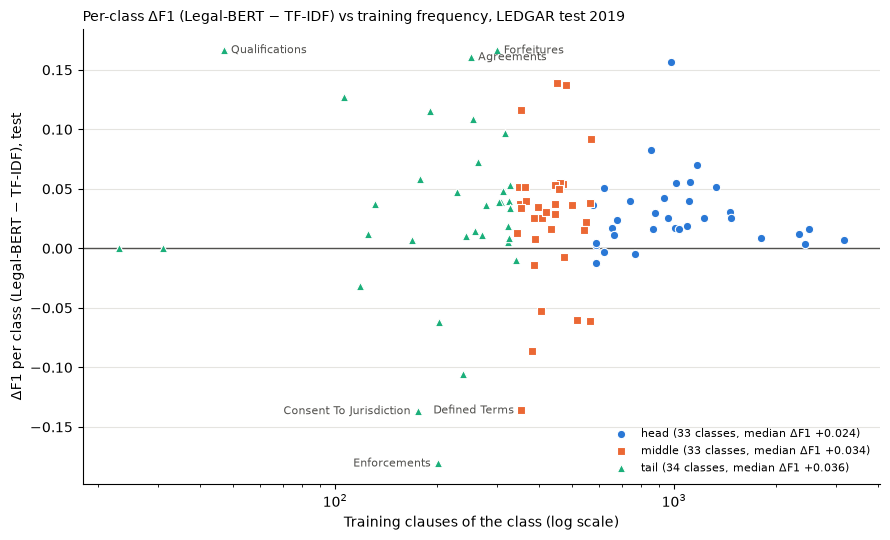

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_delta_vs_frequency(per_class, ax=ax)
ax.set_title("Per-class ΔF1 (Legal-BERT − TF-IDF) vs training frequency, LEDGAR test 2019", fontsize=10, loc="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "error_analysis_delta_f1_vs_frequency.png", dpi=150)
plt.show()

## 3. Most frequent confusions of Legal-BERT

Top 10 (true → predicted) pairs. Does TF-IDF make the same mistake? `other_same_clauses` = of these exact clauses,
how many TF-IDF also assigns to the same wrong class; `other_pair_count` = TF-IDF's own count for that pair over the
whole test set.

In [6]:
confusions = top_confusions(labels, pred_bert, label_names, other_pred=pred_tfidf, k=10)
confusions = confusions.rename(columns={"other_same_clauses": "tfidf_same_clauses", "other_pair_count": "tfidf_pair_count"})
confusions.round(4).to_csv(RESULTS_DIR / "error_analysis_confusions.csv", index=False)
display(confusions.round(3))
print(f"Top 10 pairs = {confusions['count'].sum()} of {(pred_bert != labels).sum()} Legal-BERT test errors")

,true,pred,true_name,pred_name,count,share_of_true,tfidf_same_clauses,tfidf_pair_count
0,4,47,Applicable Laws,Governing Laws,41,0.774,41,42
1,86,99,Tax Withholdings,Withholdings,26,0.347,16,24
2,28,29,Defined Terms,Definitions,25,0.446,13,18
3,99,86,Withholdings,Tax Withholdings,25,0.234,6,10
4,52,38,Integration,Entire Agreements,24,0.407,23,28
5,60,2,Modifications,Amendments,21,0.382,19,24
6,98,76,Warranties,Representations,21,0.216,9,11
7,84,13,Successors,Binding Effects,20,0.208,20,21
8,29,28,Definitions,Defined Terms,18,0.151,5,9
9,63,97,No Waivers,Waivers,18,0.214,15,28


Top 10 pairs = 239 of 1283 Legal-BERT test errors


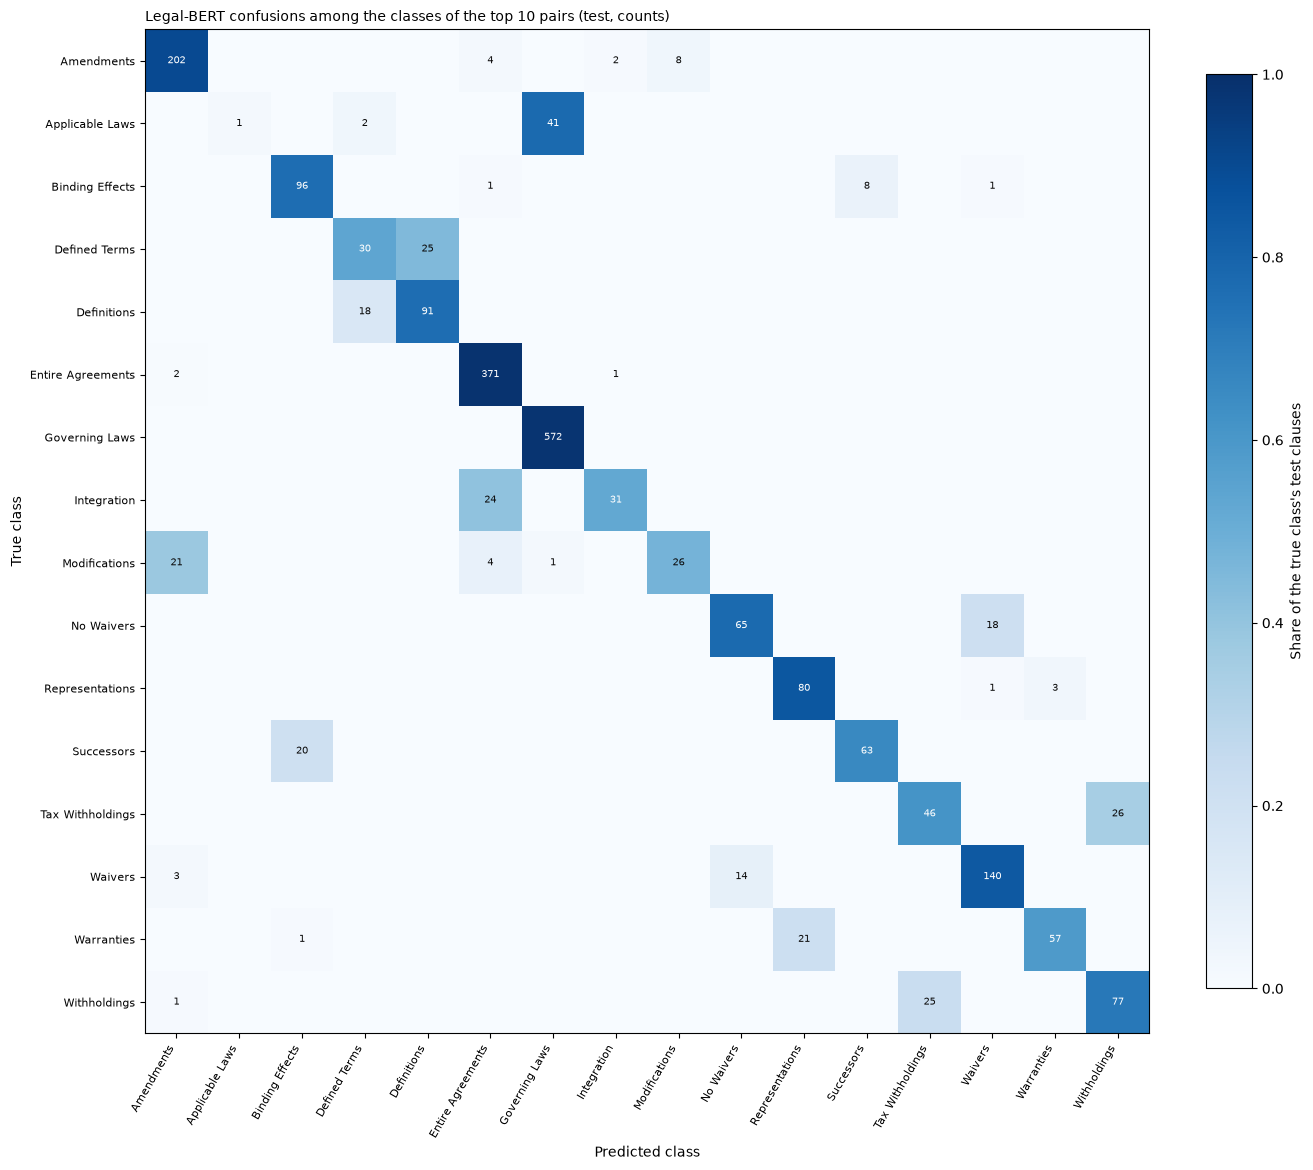

In [7]:
involved = list(dict.fromkeys([*confusions["true"], *confusions["pred"]]))
involved = sorted(involved, key=lambda c: label_names[c])
fig, ax = plt.subplots(figsize=(0.55 * len(involved) + 4.5, 0.55 * len(involved) + 3))
plot_confusion_subset(labels, pred_bert, involved, label_names, ax=ax)
ax.set_title("Legal-BERT confusions among the classes of the top 10 pairs (test, counts)", fontsize=10, loc="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "error_analysis_confusions.png", dpi=150)
plt.show()

## 4. Truncation: are clauses longer than 256 tokens harder?

Legal-BERT was trained and evaluated with `max_length = 256`: anything beyond is cut. Lengths are counted with the
model's own tokenizer (same Hub revision as the run), special tokens included, without truncation. TF-IDF sees the
whole clause, so it is the control: a gap that exists for both models is length / topic difficulty, not truncation.

In [8]:
bert_config = load_run(BERT_RUN)[0]
MAX_LENGTH = bert_config["max_length"]
test_df["n_tokens"] = token_lengths(bert_config["model_name"], test_df["text"], revision=bert_config["model_revision"])
print(f"{MAX_LENGTH=}; test clauses longer than {MAX_LENGTH} tokens: "
      f"{(test_df['n_tokens'] > MAX_LENGTH).sum()} ({(test_df['n_tokens'] > MAX_LENGTH).mean():.1%})")

truncation = error_rate_by_length(labels, {"legal-bert": pred_bert, "tfidf": pred_tfidf}, test_df["n_tokens"],
                                  MAX_LENGTH)
truncation.round(4).to_csv(RESULTS_DIR / "error_analysis_truncation.csv", index=False)
display(truncation.round(4))

MAX_LENGTH=256; test clauses longer than 256 tokens: 1083 (10.8%)


,model,length_group,n,n_errors,error_rate
0,legal-bert,<= 256 tokens,8917,1163,0.1304
1,legal-bert,> 256 tokens,1083,120,0.1108
2,tfidf,<= 256 tokens,8917,1364,0.1530
3,tfidf,> 256 tokens,1083,150,0.1385


## 5. Reading 20 Legal-BERT errors

Stratified random sample (seed 42): 10 **high-confidence** errors (`proba_pred` ≥ 0.892, the A9 threshold: these
would be labelled automatically without human review) and 10 **low-confidence** errors (sent to review). Text is
truncated to its first 300 characters for display; the tag was given after reading the full clause.

**The tags are an analyst reading, to be reviewed** (not a lawyer's annotation, not a measured rate). Vocabulary:
*overlapping labels* (both classes plausibly fit), *generic label* (true or predicted class is a catch-all such as
"Miscellaneous" / "Agreements"), *multi-topic clause*, *truncated* (key content past 256 tokens),
*possibly mislabelled* (the predicted class reads as at least as correct as the gold one), *model error* (the gold
label is clearly right).

In [9]:
calibration = json.loads((RESULTS_DIR / f"calibration_{BERT_RUN}.json").read_text())
THRESHOLD = next(p["threshold"] for p in calibration["operating_points"]
                 if p["target_precision"] == calibration["recommended_target_precision"])
print(f"{THRESHOLD=} (chosen on validation)")

sample = sample_errors(bert, THRESHOLD, n_per_group=10).merge(test_df[["idx", "text", "n_tokens"]], on="idx")
sample["true_name"] = sample["label"].map(lambda i: label_names[i])
sample["pred_name"] = sample["pred"].map(lambda i: label_names[i])
sample["text_300"] = sample["text"].str.slice(0, 300)

THRESHOLD=0.892 (chosen on validation)


In [10]:
# Analyst reading (Robin, 25/10/2026), TO BE REVIEWED: idx -> (tag, short note), given after reading the full clause
TAGS = {
    # high confidence (>= threshold: would be labelled automatically)
    8573: ("generic label", "pure counterparts / e-signature clause; gold is the catch-all Miscellaneous"),
    2094: ("overlapping labels", "good-faith cooperation duty; Further Assurances and Cooperation both fit"),
    1281: ("overlapping labels", "invoicing and payment of a reviewer's fees; Expenses vs Payments"),
    6467: ("overlapping labels", "amendment power of the Committee; Modifications vs Amendments are near-synonyms"),
    1201: ("overlapping labels", "one-sentence entire-agreement clause; Integration vs Entire Agreements are synonyms"),
    6955: ("multi-topic clause", "duty to forward notices of violation of laws; notice and compliance topics mixed"),
    4653: ("generic label", "representation on retiree benefits and 280G; gold is the catch-all Miscellaneous"),
    4690: ("overlapping labels", "no modification except in writing; Modifications vs Amendments"),
    1239: ("overlapping labels", "injunction / specific performance clause; prediction is the more specific label"),
    7639: ("overlapping labels", "condition that fees and expenses are paid; mentions both labels"),
    # low confidence (< threshold: sent to human review)
    3957: ("overlapping labels", "written-instrument amendment / waiver; Modifications vs Amendments"),
    3722: ("overlapping labels", "injunctive relief and specific performance; mirror of idx 1239"),
    5370: ("overlapping labels", "legal, valid and binding, enforceable (bankruptcy exception); Binding Effects vs Enforceability"),
    4793: ("truncated", "457-word inspection clause; the termination right comes at the very end"),
    4275: ("multi-topic clause", "organisation, authority, authorisation and enforceability in one representation"),
    8007: ("multi-topic clause", "RSU vesting schedule and forfeiture on termination in one clause"),
    9250: ("overlapping labels", "capitalised terms incorporated by reference; Defined Terms vs Definitions"),
    6317: ("overlapping labels", "tax-related items remain the participant's liability; mentions withholding"),
    7644: ("overlapping labels", "exclusive jurisdiction and service of process; three jurisdiction labels overlap"),
    1837: ("possibly mislabelled", "clause is about tax withholding on RSUs; predicted Tax Withholdings reads as correct"),
}


In [11]:
assert set(TAGS) == set(sample["idx"]), "one tag per sampled error"
sample["tag"] = sample["idx"].map(lambda i: TAGS[i][0])
sample["note"] = sample["idx"].map(lambda i: TAGS[i][1])
sample["tag_status"] = "analyst reading, to be reviewed"
sample["tfidf_pred_name"] = sample["idx"].map(lambda i: label_names[pred_tfidf[i]])
reading = sample[["confidence_group", "idx", "true_name", "pred_name", "tfidf_pred_name", "proba_pred", "n_tokens",
                  "text_300", "tag", "note", "tag_status"]]
reading.round(4).to_csv(RESULTS_DIR / "error_analysis_reading.csv", index=False)
display(reading.round(3))
display(reading.groupby(["tag", "confidence_group"]).size().unstack(fill_value=0))
print(f"TF-IDF makes the same wrong prediction on {(reading['tfidf_pred_name'] == reading['pred_name']).sum()} of 20")

,confidence_group,idx,true_name,pred_name,tfidf_pred_name,proba_pred,n_tokens,text_300,tag,note,tag_status
0,high,8573,Miscellaneous,Counterparts,Counterparts,0.996,120,"This Agreement may be executed in two or more counterparts, each of which will be deemed to be an original copy of this Agreement, and all of which, when taken together, shall be deemed to constitute one and the same agreement. The exchange of copies of this Agreement and of signature pages by facsi",generic label,pure counterparts / e-signature clause; gold is the catch-all Miscellaneous,"analyst reading, to be reviewed"
1,high,2094,Further Assurances,Cooperation,Cooperation,0.984,44,The Parties will use good faith efforts to cooperate with each other in all matters relating to the provision and receipt of the Transition Services. Such cooperation shall include exchanging information and performing true-ups and adjustments.,overlapping labels,good-faith cooperation duty; Further Assurances and Cooperation both fit,"analyst reading, to be reviewed"
2,high,1281,Expenses,Payments,Payments,0.977,205,"The Asset Representations Reviewer shall submit reasonably detailed invoices to the Servicer for any amounts owed to it under this Agreement. To the extent not paid by the Servicer within sixty (60) calendar days following the receipt of a detailed invoice on the due date therefor hereunder, the fee",overlapping labels,invoicing and payment of a reviewer's fees; Expenses vs Payments,"analyst reading, to be reviewed"
3,high,6467,Modifications,Amendments,Amendments,0.963,233,"The Committee may amend this Agreement at any time and from time to time without the consent of the Participant; provided, however that no such amendment may materially and adversely affect the rights of the Participant without his or her consent; and provided, further, that the Company may change o",overlapping labels,amendment power of the Committee; Modifications vs Amendments are near-synonyms,"analyst reading, to be reviewed"
4,high,1201,Integration,Entire Agreements,Entire Agreements,0.960,30,"Except as stated herein, this is the parties’ entire agreement on the subject matter hereof, superseding all prior representations, negotiations or agreements.",overlapping labels,one-sentence entire-agreement clause; Integration vs Entire Agreements are synonyms,"analyst reading, to be reviewed"
5,high,6955,Notices,Compliance With Laws,Compliance With Laws,0.942,49,"Seller will deliver to Buyer, promptly after receipt, any notice of violation of any laws applicable (or alleged to be applicable) to any Real Property, or any part thereof, including, without limitation, any noncompliance with Environmental Laws.",multi-topic clause,duty to forward notices of violation of laws; notice and compliance topics mixed,"analyst reading, to be reviewed"
6,high,4653,Miscellaneous,Benefits,Insurances,0.936,120,"Neither the Borrower nor any Subsidiary nor any Plan provides for or promises retiree, medical, disability, or life insurance benefits to any current or former employee, officer, or director of the Borrower or any Subsidiary other than continuation coverage required by Section 4980B of the Code. Ne",generic label,representation on retiree benefits and 280G; gold is the catch-all Miscellaneous,"analyst reading, to be reviewed"
7,high,4690,Modifications,Amendments,Amendments,0.934,39,"No provisions of this Agreement may be modified, amended, or terminated, except in a writing signed by Employee and by either the successor Chief Executive Officer or Chief Financial Officer of Energy Focus.",overlapping labels,no modification except in writing; Modifications vs Amendments,"analyst reading, to be reviewed"
8,high,1239,Remedies,Specific Performance,Specific Performance,0.925,89,The parties hereto agree that irreparable damage may occur if any provision of this Agreement were not performed in accordance with the terms hereof or thereof and that the parties shall be entitled to seek an injunction to prevent breaches

confidence_group,high,low
tag,,
generic label,2,0
multi-topic clause,1,2
overlapping labels,7,6
possibly mislabelled,0,1
truncated,0,1


TF-IDF makes the same wrong prediction on 14 of 20


## 6. Findings (numbers from the CSVs written above)

1. **The gain over TF-IDF is spread evenly across frequency groups**, not concentrated on rare classes: mean per-class
   ΔF1 +0.0295 (head), +0.0250 (middle), +0.0298 (tail). Tail classes remain the weakest in absolute terms (mean
   Legal-BERT F1 0.668 vs 0.901 for head). Legal-BERT is better or tied on 84 classes; the largest gains are on
   Forfeitures (+0.166, 52 test clauses), Agreements (+0.161), General (+0.157) and Vesting (+0.139). The top gain,
   Qualifications (+0.167), rests on 5 test clauses only.
2. **TF-IDF is better on 16 classes**, mostly in families of near-synonym labels: Enforcements (−0.181), Consent To
   Jurisdiction (−0.137), Defined Terms (−0.136), Submission To Jurisdiction (−0.105), Tax Withholdings (−0.087),
   Jurisdictions, Definitions, Withholdings. These per-class differences are descriptive (no test per class).
3. **Errors concentrate on pairs of overlapping labels, and the baseline shares them.** The 10 most frequent
   confusions account for 239 of the 1,283 Legal-BERT errors; 77.4 % of the Applicable Laws clauses (41) are
   predicted Governing Laws, and several pairs run both ways (Tax Withholdings ↔ Withholdings 26 / 25, Defined Terms
   ↔ Definitions 25 / 18). On 167 of these 239 clauses TF-IDF predicts the same wrong class: this looks like a property
   of the label set more than of either model.
4. **Truncation at 256 tokens is not a major error source.** The 1,083 test clauses (10.8 %) longer than 256 tokens
   have a *lower* Legal-BERT error rate (11.1 %) than shorter ones (13.0 %); TF-IDF, which sees whole clauses, shows the
   same pattern (13.9 % vs 15.3 %).
5. **Reading 20 errors** (analyst reading, to be reviewed): 13 overlapping labels, 3 multi-topic clauses, 2 generic
   labels (Miscellaneous), 1 truncated, 1 possibly mislabelled. Among the 10 high-confidence errors (which the 0.892
   threshold would label automatically), 7 are overlapping labels and 2 generic labels. On 14 of the 20 clauses
   TF-IDF made the same wrong prediction.

**Limitations.** One test set and one run per model; per-class F1 on small classes is noisy; the 20 tags come from
one non-lawyer reader and a sample of 20, so they are illustrations, not rates.
